# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Ellen Tri Alfiana Salua
- **Email:** elensalua@gmail.com
- **ID Dicoding:** DS323B6X0507
## Pertanyaan Bisnis

### Pertanyaan 1
Bagaimana tren total penyewaan sepeda (`cnt`) per bulan dan per musim pada tahun 2011 dibandingkan 2012, dan kondisi cuaca (`weathersit`) mana yang paling menurunkan rata-rata penyewaan harian selama periode 2011–2012?

**SMART:**
- **Specific** — Objek: `cnt`; dimensi: bulan, musim, cuaca.
- **Measurable** — Diukur via agregasi `sum`/`mean` kolom `cnt` (unit: penyewaan).
- **Action-Oriented** — Menentukan kapan armada ditambah & strategi cuaca buruk.
- **Relevant** — Tren & cuaca = faktor eksternal utama permintaan.
- **Time-bound** — Periode dataset 2011–2012.

### Pertanyaan 2
Pada jam berapa permintaan penyewaan mencapai puncaknya pada hari kerja dibandingkan hari libur selama 2011–2012, dan bagaimana perbandingan kontribusi pengguna `registered` vs `casual` pada jam-jam tersebut?

**SMART:**
- **Specific** — Objek: `cnt` per jam (`hr`); dimensi: jenis hari & tipe pengguna.
- **Measurable** — `groupby('hr').mean()`, `sum` per tipe pengguna (unit: penyewaan/jam).
- **Action-Oriented** — Menentukan jadwal redistribusi armada per jam.
- **Relevant** — Pola per jam = dasar operasional harian.
- **Time-bound** — Periode 2011–2012.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

print('pandas    :', pd.__version__)
print('numpy     :', np.__version__)
print('seaborn   :', sns.__version__)

pandas    : 3.1.1
numpy     : 2.4.6
seaborn   : 0.13.2


### Gathering Data
Memuat dua berkas: `day.csv` (agregasi harian, 731 baris) dan `hour.csv` (agregasi per jam, 17.379 baris, tambahan kolom `hr`).

In [27]:
day_df  = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

print('=== day_df ===  shape:', day_df.shape)
display(day_df.head())
print('\n=== hour_df ===  shape:', hour_df.shape)
display(hour_df.head())

=== day_df ===  shape: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



=== hour_df ===  shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight — Gathering Data**
- `day_df` = 731 baris (2 tahun × ~365 hari), `hour_df` = 17.379 baris.
- Bila lengkap 731×24 = 17.544 jam → **165 jam tidak tercatat** (sistem tidak beroperasi / tidak ada transaksi).
- `cnt` = `casual` + `registered` (verifikasi: 16 = 3 + 13).
- Nilai `temp`, `atemp`, `hum`, `windspeed` masih ternormalisasi 0–1; `dteday` masih `object`; `season`/`weathersit`/`weekday` masih kode angka → perlu cleaning.

### Assessing Data
Pemeriksaan kualitas data dengan: `info()`, `isnull().sum()`, `duplicated().sum()`, `describe()`, cek tipe data, cek nilai unik kategorikal, cek outlier (IQR + boxplot), dan cek konsistensi `day_df` ↔ `hour_df`.

In [28]:
print('===== INFO day_df ====='); day_df.info()
print('\n===== INFO hour_df ====='); hour_df.info()

===== INFO day_df =====
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB

===== INFO hour_df =====
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to

In [29]:
for name, df in [('day_df', day_df), ('hour_df', hour_df)]:
    print(f'===== {name} =====')
    print('Missing value:\n', df.isnull().sum())
    print('Duplikat baris :', df.duplicated().sum())
    print('Duplikat instant:', df['instant'].duplicated().sum(), '\n')

display(day_df.describe()); display(hour_df.describe())

===== day_df =====
Missing value:
 instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Duplikat baris : 0
Duplikat instant: 0 

===== hour_df =====
Missing value:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Duplikat baris : 0
Duplikat instant: 0 



,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [30]:
for col in ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']:
    print(f'{col:12s} -> {sorted(day_df[col].unique())}')

season       -> [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
yr           -> [np.int64(0), np.int64(1)]
mnth         -> [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
holiday      -> [np.int64(0), np.int64(1)]
weekday      -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
workingday   -> [np.int64(0), np.int64(1)]
weathersit   -> [np.int64(1), np.int64(2), np.int64(3)]


In [31]:
def cek_outlier(df, kolom):
    q1, q3 = df[kolom].quantile(0.25), df[kolom].quantile(0.75)
    iqr = q3 - q1
    bawah, atas = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((df[kolom] < bawah) | (df[kolom] > atas)).sum()
    return pd.Series({'Q1': q1, 'Q3': q3, 'IQR': iqr,
                      'Batas Bawah': bawah, 'Batas Atas': atas,
                      'Jumlah Outlier': n,
                      'Persentase (%)': round(n/len(df)*100, 2)})

kolom_num = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
display(pd.DataFrame({k: cek_outlier(day_df, k) for k in kolom_num}).T)

,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
temp,0.337083,0.655417,0.318333,-0.140416,1.132916,0.0,0.00
atemp,0.337842,0.608602,0.270760,-0.068297,1.014741,0.0,0.00
hum,0.520000,0.730209,0.210209,0.204687,1.045521,2.0,0.27
windspeed,0.134950,0.233214,0.098265,-0.012447,0.380611,13.0,1.78
casual,315.500000,1096.000000,780.500000,-855.250000,2266.750000,44.0,6.02
registered,2497.000000,4776.500000,2279.500000,-922.250000,8195.750000,0.0,0.00
cnt,3152.000000,5956.000000,2804.000000,-1054.000000,10162.000000,0.0,0.00


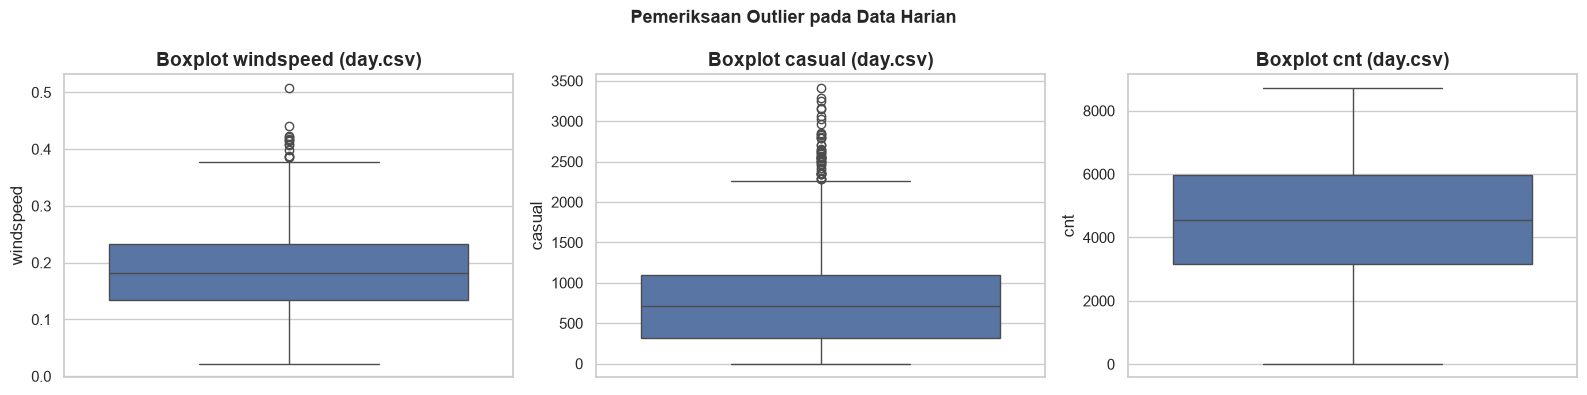

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, kol in zip(axes, ['windspeed', 'casual', 'cnt']):
    sns.boxplot(data=day_df, y=kol, ax=ax, color='#4C72B0')
    ax.set_title(f'Boxplot {kol} (day.csv)')
plt.suptitle('Pemeriksaan Outlier pada Data Harian', fontweight='bold')
plt.tight_layout(); plt.show()

In [33]:
daily_from_hour = hour_df.groupby('dteday', as_index=False)['cnt'].sum()
cek = daily_from_hour.merge(day_df[['dteday','cnt']], on='dteday',
                            suffixes=('_hour','_day'))
print('Hari beda total cnt :', (cek['cnt_hour'] != cek['cnt_day']).sum())
print('Total cnt day_df   :', day_df['cnt'].sum())
print('Total cnt hour_df  :', hour_df['cnt'].sum())
jam_per_hari = hour_df.groupby('dteday')['hr'].count()
print('Hari < 24 jam      :', (jam_per_hari < 24).sum())
print('Total jam hilang   :', 731*24 - hour_df.shape[0])

Hari beda total cnt : 0
Total cnt day_df   : 3292679
Total cnt hour_df  : 3292679
Hari < 24 jam      : 76
Total jam hilang   : 165


**Insight — Assessing Data**
Masalah yang ditemukan:
1. `dteday` bertipe **object** (string), bukan datetime → sulit analisis waktu.
2. Kolom kategorikal masih **kode angka** (`season` 1–4, `weathersit` 1–4, `weekday` 0–6, `yr` 0/1) → rawan salah tafsir.
3. `temp/atemp/hum/windspeed` masih **ternormalisasi** (0–1) → tidak terbaca dalam satuan nyata.
4. Terdapat **outlier** pada `windspeed`, `casual`, `registered`, `cnt` (IQR + boxplot).
5. `hour_df` **tidak lengkap 24 jam per hari** (165 jam hilang).

Konsistensi day↔hour: total `cnt` per hari **identik** (0 hari berbeda) → aman dianalisis berdampingan. Tidak ada missing value maupun duplikat.

**Steps to Take:**
- Ubah `dteday` → datetime.
- Mapping `season`, `weathersit`, `weekday`, `yr`, `mnth` → label berurutan.
- Denormalisasi: `temp`×41 °C, `atemp`×50 °C, `hum`×100 %, `windspeed`×67 km/jam.
- **Biarkan outlier** (permintaan puncak valid = insight bisnis), cukup **tandai** dengan kolom flag.
- Tambah kolom `day_type` (Hari Kerja / Hari Libur) dari `workingday`.
- Tidak perlu handle missing value / duplikasi (tidak ada).

In [34]:
season_map    = {1:'Semi', 2:'Panas', 3:'Gugur', 4:'Dingin'}
yr_map        = {0:2011, 1:2012}
weather_map   = {1:'Cerah', 2:'Berkabut', 3:'Hujan Ringan', 4:'Hujan Lebat'}
weekday_map   = {0:'Minggu',1:'Senin',2:'Selasa',3:'Rabu',4:'Kamis',5:'Jumat',6:'Sabtu'}
month_map     = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'Mei',6:'Jun',
                 7:'Jul',8:'Agu',9:'Sep',10:'Okt',11:'Nov',12:'Des'}
urutan_bulan = list(month_map.values())
urutan_musim = ['Semi','Panas','Gugur','Dingin']
urutan_cuaca = ['Cerah','Berkabut','Hujan Ringan','Hujan Lebat']
urutan_hari  = ['Senin','Selasa','Rabu','Kamis','Jumat','Sabtu','Minggu']

def clean_bike(df):
    df = df.copy()
    df['dteday']     = pd.to_datetime(df['dteday'])
    df['season']     = pd.Categorical(df['season'].map(season_map), urutan_musim, ordered=True)
    df['weathersit'] = pd.Categorical(df['weathersit'].map(weather_map), urutan_cuaca, ordered=True)
    df['weekday']    = pd.Categorical(df['weekday'].map(weekday_map), urutan_hari, ordered=True)
    df['mnth']       = pd.Categorical(df['mnth'].map(month_map), urutan_bulan, ordered=True)
    df['yr']         = df['yr'].map(yr_map).astype(int)
    df['holiday']    = df['holiday'].map({0:'Bukan Libur', 1:'Libur'})
    df['workingday'] = df['workingday'].map({0:'Hari Libur', 1:'Hari Kerja'})
    df['temp_C']     = (df['temp']*41).round(2)
    df['atemp_C']    = (df['atemp']*50).round(2)
    df['hum_pct']    = (df['hum']*100).round(2)
    df['wind_kmh']   = (df['windspeed']*67).round(2)
    df['day_type']   = np.where(df['workingday']=='Hari Kerja', 'Hari Kerja', 'Hari Libur')
    df['year']       = df['dteday'].dt.year
    df['month_num']  = df['dteday'].dt.month
    for kol in ['wind_kmh', 'cnt']:
        q1, q3 = df[kol].quantile(0.25), df[kol].quantile(0.75)
        iqr = q3 - q1
        df[f'{kol}_outlier'] = ((df[kol] < q1-1.5*iqr) | (df[kol] > q3+1.5*iqr))
    return df

day_clean  = clean_bike(day_df)
hour_clean = clean_bike(hour_df)
print('Shape day_clean :', day_clean.shape)
print('Shape hour_clean:', hour_clean.shape)
display(day_clean.head())

Shape day_clean : (731, 25)
Shape hour_clean: (17379, 26)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,...,cnt,temp_C,atemp_C,hum_pct,wind_kmh,day_type,year,month_num,wind_kmh_outlier,cnt_outlier
0,1,2011-01-01,Semi,2011,Jan,Bukan Libur,Sabtu,Hari Libur,Berkabut,0.344167,...,985,14.11,18.18,80.58,10.75,Hari Libur,2011,1,False,False
1,2,2011-01-02,Semi,2011,Jan,Bukan Libur,Minggu,Hari Libur,Berkabut,0.363478,...,801,14.90,17.69,69.61,16.65,Hari Libur,2011,1,False,False
2,3,2011-01-03,Semi,2011,Jan,Bukan Libur,Senin,Hari Kerja,Cerah,0.196364,...,1349,8.05,9.47,43.73,16.64,Hari Kerja,2011,1,False,False
3,4,2011-01-04,Semi,2011,Jan,Bukan Libur,Selasa,Hari Kerja,Cerah,0.200000,...,1562,8.20,10.61,59.04,10.74,Hari Kerja,2011,1,False,False
4,5,2011-01-05,Semi,2011,Jan,Bukan Libur,Rabu,Hari Kerja,Cerah,0.226957,...,1600,9.31,11.46,43.70,12.52,Hari Kerja,2011,1,False,False


In [35]:
print('===== INFO day_clean ====='); day_clean.info()
print('\n===== Nilai unik kategorikal =====')
for col in ['season','yr','mnth','weathersit','workingday']:
    print(f'{col:12s} -> {list(day_clean[col].dropna().unique())}')
display(day_clean[['temp_C','atemp_C','hum_pct','wind_kmh','cnt']].describe().round(2))
print('\nDistribusi day_type:'); print(hour_clean['day_type'].value_counts())

===== INFO day_clean =====
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   instant           731 non-null    int64         
 1   dteday            731 non-null    datetime64[us]
 2   season            731 non-null    category      
 3   yr                731 non-null    int64         
 4   mnth              731 non-null    category      
 5   holiday           731 non-null    str           
 6   weekday           731 non-null    category      
 7   workingday        731 non-null    str           
 8   weathersit        731 non-null    category      
 9   temp              731 non-null    float64       
 10  atemp             731 non-null    float64       
 11  hum               731 non-null    float64       
 12  windspeed         731 non-null    float64       
 13  casual            731 non-null    int64         
 14  registered

,temp_C,atemp_C,hum_pct,wind_kmh,cnt
count,731.00,731.00,731.00,731.00,731.00
mean,20.31,23.72,62.79,12.76,4504.35
std,7.51,8.15,14.24,5.19,1937.21
min,2.42,3.95,0.00,1.50,22.00
25%,13.82,16.90,52.00,9.04,3152.00
50%,20.43,24.34,62.67,12.13,4548.00
75%,26.88,30.43,73.02,15.62,5956.00
max,35.33,42.04,97.25,34.00,8714.00



Distribusi day_type:
day_type
Hari Kerja    11865
Hari Libur     5514
Name: count, dtype: int64


**Insight — Cleaning Data**
- `dteday` kini `datetime64` → siap untuk analisis deret waktu.
- Kategori berlabel dan **berurutan** → grafik tidak salah urut.
- Suhu °C, kelembapan %, angin km/jam → mudah dikomunikasikan.
- Outlier **ditandai** (`*_outlier`) tapi tidak dihapus (permintaan puncak = insight bisnis).
- Kolom `day_type` siap untuk analisis per jenis hari.

### EDA — Pertanyaan 1
Fokus: tren bulanan, 2011 vs 2012, pengaruh musim dan cuaca.

In [36]:
tahun = day_clean.groupby('yr').agg(
    total=('cnt','sum'), rata_harian=('cnt','mean'),
    median=('cnt','median'), hari=('cnt','count')).round(2)
tahun['pertumbuhan_%'] = ((tahun['total']/tahun.loc[2011,'total'] - 1)*100).round(2)
display(tahun)

,total,rata_harian,median,hari,pertumbuhan_%
yr,,,,,
2011,1243103,3405.76,3740.0,365,0.00
2012,2049576,5599.93,5927.0,366,64.88


In [37]:
tren_bulanan = day_clean.pivot_table(index='mnth', columns='yr', values='cnt',
                                     aggfunc='sum', observed=False)
tren_bulanan.index.name = 'Bulan'; tren_bulanan.columns.name = 'Tahun'
display(tren_bulanan)
for y in [2011, 2012]:
    print(f'[{y}] tertinggi:', tren_bulanan[y].idxmax(), '-', int(tren_bulanan[y].max()),
          '| terendah:', tren_bulanan[y].idxmin(), '-', int(tren_bulanan[y].min()))

Tahun,2011,2012
Bulan,,
Jan,38189,96744
Feb,48215,103137
Mar,64045,164875
Apr,94870,174224
Mei,135821,195865
Jun,143512,202830
Jul,141341,203607
Agu,136691,214503
Sep,127418,218573


[2011] tertinggi: Jun - 143512 | terendah: Jan - 38189
[2012] tertinggi: Sep - 218573 | terendah: Jan - 96744


In [38]:
musim_stats = day_clean.groupby('season', observed=False).agg(
    total=('cnt','sum'), rata_harian=('cnt','mean'), hari=('cnt','count')).round(2)
musim_stats['kontribusi_%'] = (musim_stats['total']/day_clean['cnt'].sum()*100).round(2)
display(musim_stats)

,total,rata_harian,hari,kontribusi_%
season,,,,
Semi,471348,2604.13,181,14.32
Panas,918589,4992.33,184,27.90
Gugur,1061129,5644.30,188,32.23
Dingin,841613,4728.16,178,25.56


In [39]:
cuaca_stats = day_clean.groupby('weathersit', observed=False).agg(
    total=('cnt','sum'), rata_harian=('cnt','mean'), hari=('cnt','count')).round(2)
baseline = cuaca_stats.loc['Cerah','rata_harian']
cuaca_stats['penurunan_vs_cerah_%'] = ((cuaca_stats['rata_harian']/baseline - 1)*100).round(2)
display(cuaca_stats)

,total,rata_harian,hari,penurunan_vs_cerah_%
weathersit,,,,
Cerah,2257952,4876.79,463,0.00
Berkabut,996858,4035.86,247,-17.24
Hujan Ringan,37869,1803.29,21,-63.02
Hujan Lebat,0,NaN,0,NaN


In [40]:
kol_corr = ['cnt','temp_C','atemp_C','hum_pct','wind_kmh']
matriks = day_clean[kol_corr].corr().round(3)
display(matriks)
print('\nKorelasi terhadap cnt:')
print(matriks['cnt'].drop('cnt').sort_values(ascending=False).round(3))

,cnt,temp_C,atemp_C,hum_pct,wind_kmh
cnt,1.000,0.627,0.631,-0.101,-0.235
temp_C,0.627,1.000,0.992,0.127,-0.158
atemp_C,0.631,0.992,1.000,0.140,-0.184
hum_pct,-0.101,0.127,0.140,1.000,-0.249
wind_kmh,-0.235,-0.158,-0.184,-0.249,1.000



Korelasi terhadap cnt:


atemp_C     0.631
temp_C      0.627
hum_pct    -0.101
wind_kmh   -0.235
Name: cnt, dtype: float64


**Insight — EDA Pertanyaan 1**
- Total penyewaan **2012 ≈ 2× 2011** (tumbuh ±65%). Permintaan melesat.
- Musim **Gugur** kontribusi tertinggi, disusul Panas; **Semi** terendah.
- Tren bulanan: naik dari Jan, **puncak Agustus–September**, turun Nov–Des.
- Cuaca **Cerah** rata-rata tertinggi; **Hujan Ringan & Berkabut** menekan permintaan secara nyata. **Hujan Lebat** sampelnya sangat sedikit → tidak representatif.
- Korelasi: `temp_C` **+0,63** (kuat), `wind_kmh` **−0,23** (sedang), `hum_pct` **−0,10** (lemah).

### EDA — Pertanyaan 2
Fokus: pola per jam hari kerja vs hari libur, dan komposisi registered vs casual.

In [41]:
user_total = hour_clean[['casual','registered','cnt']].sum().to_frame('total')
user_total['persen_%'] = (user_total['total']/hour_clean['cnt'].sum()*100).round(2)
display(user_total)

,total,persen_%
casual,620017,18.83
registered,2672662,81.17
cnt,3292679,100.00


In [42]:
pola_jam = hour_clean.pivot_table(index='hr', columns='day_type',
                                  values='cnt', aggfunc='mean').round(2)
pola_jam.index.name = 'Jam'
display(pola_jam)
for jenis in pola_jam.columns:
    print(f'[{jenis}] tersibuk jam {pola_jam[jenis].idxmax():02d} '
          f'({pola_jam[jenis].max():.2f}) | tersepi jam '
          f'{pola_jam[jenis].idxmin():02d} ({pola_jam[jenis].min():.2f})')

day_type,Hari Kerja,Hari Libur
Jam,,
0,36.79,90.80
1,16.55,69.51
2,8.68,53.17
3,4.94,25.78
4,5.43,8.26
5,24.91,8.69
6,102.50,18.74
7,290.61,43.41
8,477.01,105.65


[Hari Kerja] tersibuk jam 17 (525.29) | tersepi jam 03 (4.94)
[Hari Libur] tersibuk jam 13 (372.73) | tersepi jam 04 (8.26)


In [43]:
komposisi = hour_clean.groupby(['day_type','hr'], observed=True)[['casual','registered']].mean().round(2)
print('Hari Kerja jam sibuk (7-9, 16-19):')
display(komposisi.loc['Hari Kerja'].loc[[7,8,9,16,17,18,19]])
print('Hari Libur siang (10-16):')
display(komposisi.loc['Hari Libur'].loc[[10,11,12,13,14,15,16]])

Hari Kerja jam sibuk (7-9, 16-19):


,casual,registered
hr,,
7,12.20,278.42
8,22.26,454.74
9,24.31,217.21
16,48.34,244.78
17,56.90,468.39
18,50.45,441.78
19,41.02,307.38


Hari Libur siang (10-16):


,casual,registered
hr,,
10,79.27,176.64
11,106.65,208.66
12,126.25,240.01
13,136.42,236.31
14,139.59,225.05
15,136.50,222.31
16,128.61,224.11


**Insight — EDA Pertanyaan 2**
- `registered` ≈ **81%**, `casual` ≈ 19% → basis utama pengguna berlangganan.
- **Hari kerja**: double-peak **08.00** & **17.00–18.00** (pola komuter).
- **Hari libur**: single-peak **12.00–14.00** (pola rekreasi) dengan kurva landai.
- Proporsi `casual` **naik signifikan di siang hari libur** → target akuisisi pengguna baru.

### Visualization & Explanatory Analysis
Prinsip desain: judul informatif, label + satuan, legend, **bar chart dari 0**, line untuk tren, palet konsisten (biru=2011/base, oranye=2012/highlight), highlight insight utama, tanpa elemen dekoratif berlebih.

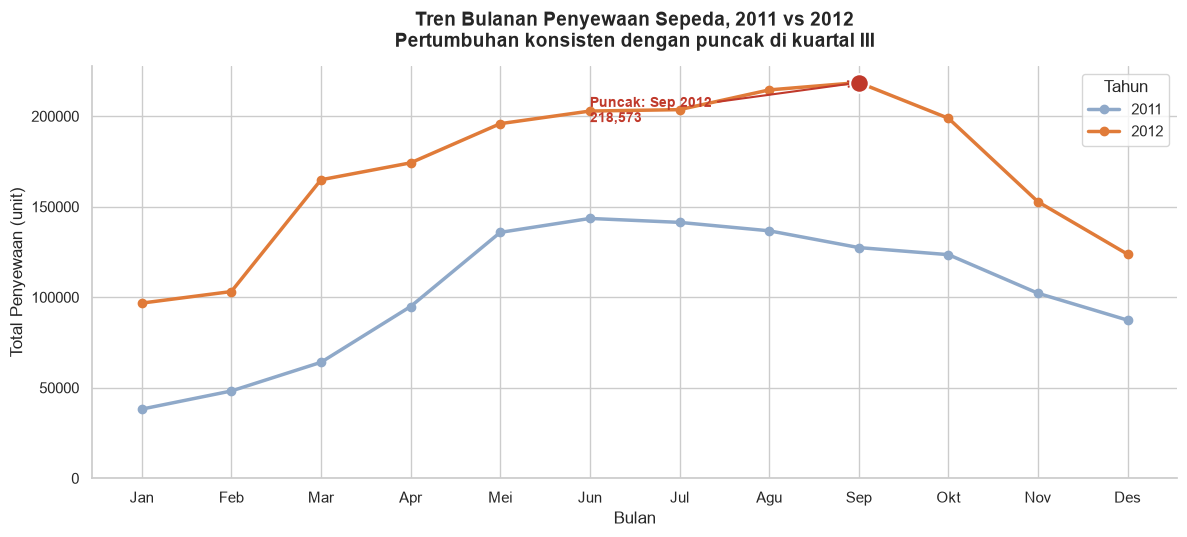

In [44]:
fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(urutan_bulan))
ax.plot(x, tren_bulanan[2011].values, marker='o', lw=2.5, color='#8FA9C9', label='2011')
ax.plot(x, tren_bulanan[2012].values, marker='o', lw=2.5, color='#E07B39', label='2012')
idx = int(np.argmax(tren_bulanan[2012].values))
ax.scatter(idx, tren_bulanan[2012].max(), s=180, color='#C0392B',
           zorder=5, edgecolor='white', linewidth=1.5)
ax.annotate(f'Puncak: {urutan_bulan[idx]} 2012\n{int(tren_bulanan[2012].max()):,}',
            xy=(idx, tren_bulanan[2012].max()),
            xytext=(idx-3, tren_bulanan[2012].max()*0.9),
            fontsize=10, fontweight='bold', color='#C0392B',
            arrowprops=dict(arrowstyle='->', color='#C0392B', lw=1.5))
ax.set_xticks(x); ax.set_xticklabels(urutan_bulan)
ax.set_xlabel('Bulan'); ax.set_ylabel('Total Penyewaan (unit)')
ax.set_title('Tren Bulanan Penyewaan Sepeda, 2011 vs 2012\n'
             'Pertumbuhan konsisten dengan puncak di kuartal III', pad=14)
ax.legend(title='Tahun'); ax.set_ylim(bottom=0)
sns.despine(); plt.tight_layout(); plt.show()

# Insight: Kurva 2012 selalu di atas 2011 (pertumbuhan sepanjang tahun); pola "bukit" musiman konsisten -> puncak Agustus-September, terendah Des-Jan. Implikasi: perencanaan armada tahunan mengikuti kurva ini.

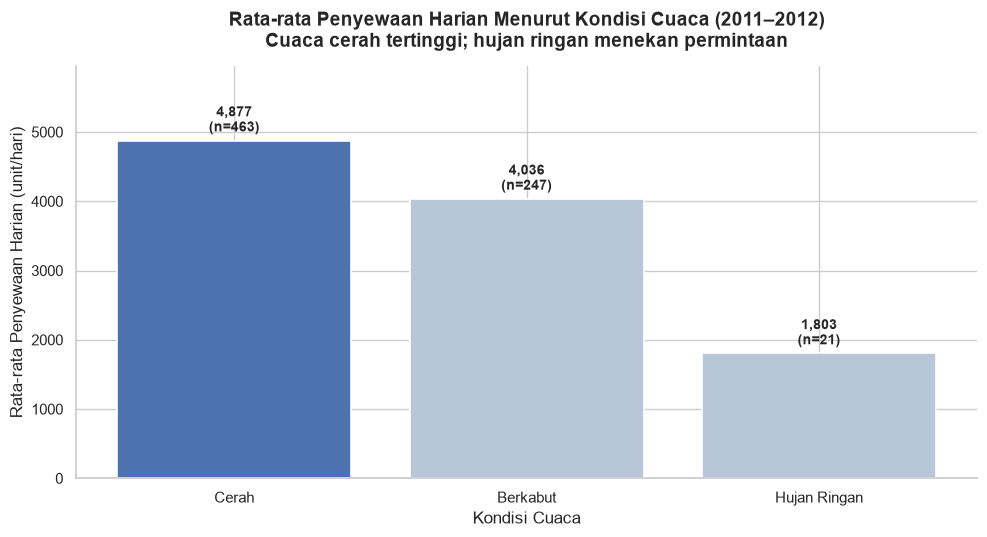

In [45]:
fig, ax = plt.subplots(figsize=(10, 5.5))
data = cuaca_stats['rata_harian']
warna = ['#4C72B0' if v == data.max() else '#B8C6D9' for v in data.values]
bars = ax.bar(data.index, data.values, color=warna, edgecolor='white', linewidth=1.2)
for bar, val, n in zip(bars, data.values, cuaca_stats['hari'].values):
    ax.text(bar.get_x()+bar.get_width()/2, val+data.max()*0.015,
            f'{val:,.0f}\n(n={n})', ha='center', va='bottom',
            fontsize=10, fontweight='bold')
ax.set_xlabel('Kondisi Cuaca'); ax.set_ylabel('Rata-rata Penyewaan Harian (unit/hari)')
ax.set_title('Rata-rata Penyewaan Harian Menurut Kondisi Cuaca (2011–2012)\n'
             'Cuaca cerah tertinggi; hujan ringan menekan permintaan', pad=14)
ax.set_ylim(0, data.max()*1.22)
sns.despine(); plt.tight_layout(); plt.show()

# Insight: Rata-rata tertinggi saat Cerah, menurun ke Berkabut dan Hujan Ringan (penurunan puluhan persen). Hujan Lebat dengan sampel sedikit tidak boleh dijadikan dasar keputusan. Implikasi: promo diskon saat Berkabut/Hujan Ringan untuk stabilkan pendapatan.

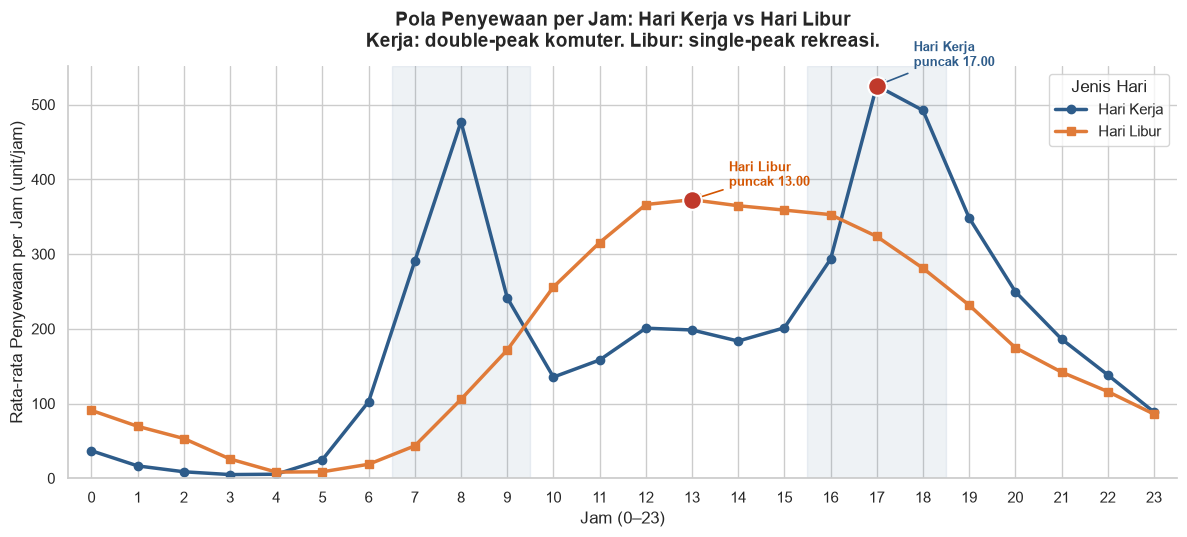

In [46]:
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(pola_jam.index, pola_jam['Hari Kerja'], marker='o', lw=2.5,
        color='#2E5C8A', label='Hari Kerja')
ax.plot(pola_jam.index, pola_jam['Hari Libur'], marker='s', lw=2.5,
        color='#E07B39', label='Hari Libur')
for jenis, wrn in [('Hari Kerja','#2E5C8A'), ('Hari Libur','#D35400')]:
    j = pola_jam[jenis].idxmax()
    ax.scatter(j, pola_jam.loc[j, jenis], s=180, color='#C0392B',
               zorder=5, edgecolor='white', linewidth=1.5)
    ax.annotate(f'{jenis}\npuncak {j:02d}.00',
                xy=(j, pola_jam.loc[j, jenis]),
                xytext=(j+0.8, pola_jam.loc[j, jenis]*1.05),
                fontsize=9, fontweight='bold', color=wrn,
                arrowprops=dict(arrowstyle='->', color=wrn, lw=1.2))
ax.axvspan(6.5, 9.5, alpha=0.08, color='#2E5C8A')
ax.axvspan(15.5, 18.5, alpha=0.08, color='#2E5C8A')
ax.set_xticks(range(0,24)); ax.set_xlim(-0.5, 23.5)
ax.set_xlabel('Jam (0–23)'); ax.set_ylabel('Rata-rata Penyewaan per Jam (unit/jam)')
ax.set_title('Pola Penyewaan per Jam: Hari Kerja vs Hari Libur\n'
             'Kerja: double-peak komuter. Libur: single-peak rekreasi.', pad=14)
ax.legend(title='Jenis Hari'); ax.set_ylim(bottom=0)
sns.despine(); plt.tight_layout(); plt.show()

# Insight: Hari kerja = dua puncak tajam (08.00, 17.00-18.00) — jam komuter. Hari libur = satu puncak lebar (12.00-14.00) — rekreasi. Strategi operasional harus dibedakan per jenis hari; menyamakan akan menyebabkan kekurangan/kelebihan sepeda.

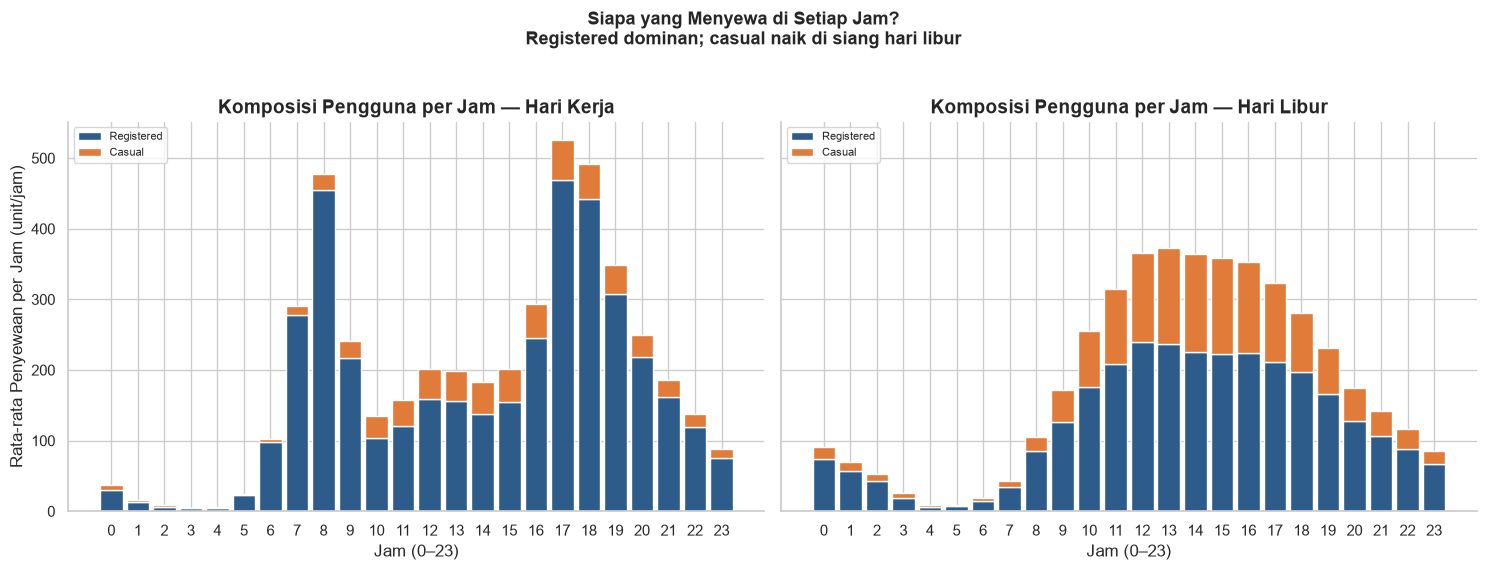

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, jenis in zip(axes, ['Hari Kerja','Hari Libur']):
    data = komposisi.loc[jenis]
    ax.bar(data.index, data['registered'], color='#2E5C8A', label='Registered', width=0.85)
    ax.bar(data.index, data['casual'], bottom=data['registered'],
           color='#E07B39', label='Casual', width=0.85)
    ax.set_xticks(range(0,24)); ax.set_xlabel('Jam (0–23)')
    ax.set_title(f'Komposisi Pengguna per Jam — {jenis}', fontweight='bold')
    ax.set_ylim(bottom=0); ax.legend(loc='upper left', fontsize=8)
    sns.despine(ax=ax)
axes[0].set_ylabel('Rata-rata Penyewaan per Jam (unit/jam)')
fig.suptitle('Siapa yang Menyewa di Setiap Jam?\n'
             'Registered dominan; casual naik di siang hari libur',
             fontweight='bold', fontsize=13, y=1.03)
plt.tight_layout(); plt.show()

# Insight: registered dominan hampir semua jam, terutama jam sibuk hari kerja. Porsi casual paling terlihat di siang hari libur — target akuisisi pengguna baru.

### Analisis Lanjutan — Binning Tingkat Permintaan & Segmentasi Waktu
**Tujuan:**
Binning manual `cnt` harian → 3 kelas (**Rendah/Sedang/Tinggi**) berbasis tertil. Memberi *bahasa operasional* sederhana untuk keputusan armada harian. Segmentasi waktu per jam (Pagi/Siang/Sore/Malam) untuk melihat jendela waktu penyumbang permintaan terbesar. Relevan langsung dengan keputusan operasional.

In [48]:
q1, q2 = day_clean['cnt'].quantile([1/3, 2/3])
print(f'Batas: Rendah < {q1:,.0f} <= Sedang < {q2:,.0f} <= Tinggi')
day_clean['demand_level'] = pd.cut(day_clean['cnt'],
    bins=[-np.inf, q1, q2, np.inf], labels=['Rendah','Sedang','Tinggi'])
print('\nDistribusi:'); print(day_clean['demand_level'].value_counts().sort_index())
ct_musim = pd.crosstab(day_clean['season'], day_clean['demand_level'])
ct_cuaca = pd.crosstab(day_clean['weathersit'], day_clean['demand_level'])
print('\nMusim × Demand:'); display(ct_musim)
print('\nCuaca × Demand:'); display(ct_cuaca)

Batas: Rendah < 3,741 <= Sedang < 5,312 <= Tinggi

Distribusi:
demand_level
Rendah    244
Sedang    244
Tinggi    243
Name: count, dtype: int64

Musim × Demand:


demand_level,Rendah,Sedang,Tinggi
season,,,
Semi,140,33,8
Panas,37,71,76
Gugur,13,79,96
Dingin,54,61,63



Cuaca × Demand:


demand_level,Rendah,Sedang,Tinggi
weathersit,,,
Cerah,121,160,182
Berkabut,104,82,61
Hujan Ringan,19,2,0


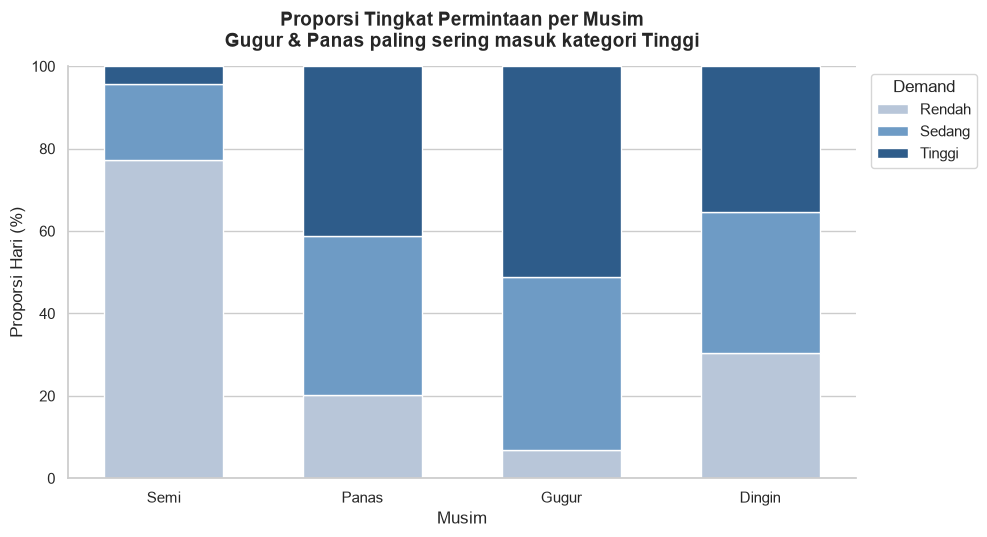

In [49]:
proporsi = ct_musim.div(ct_musim.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 5.5))
warna = {'Rendah':'#B8C6D9','Sedang':'#6E9BC5','Tinggi':'#2E5C8A'}
bottom = np.zeros(len(proporsi))
for lvl in ['Rendah','Sedang','Tinggi']:
    ax.bar(proporsi.index, proporsi[lvl], bottom=bottom, color=warna[lvl],
           label=lvl, edgecolor='white', width=0.6)
    bottom += proporsi[lvl].values
ax.set_xlabel('Musim'); ax.set_ylabel('Proporsi Hari (%)')
ax.set_title('Proporsi Tingkat Permintaan per Musim\n'
             'Gugur & Panas paling sering masuk kategori Tinggi', pad=14)
ax.set_ylim(0, 100); ax.legend(title='Demand', bbox_to_anchor=(1.01,1))
sns.despine(); plt.tight_layout(); plt.show()

In [50]:
def segmen(jam):
    if 5 <= jam < 11: return 'Pagi (05–10)'
    if 11 <= jam < 15: return 'Siang (11–14)'
    if 15 <= jam < 19: return 'Sore (15–18)'
    return 'Malam (19–04)'

urutan_seg = ['Pagi (05–10)','Siang (11–14)','Sore (15–18)','Malam (19–04)']
hour_clean['time_segment'] = pd.Categorical(hour_clean['hr'].apply(segmen),
                                            urutan_seg, ordered=True)
seg_stats = hour_clean.groupby(['day_type','time_segment'], observed=True).agg(
    total=('cnt','sum'), rata_per_jam=('cnt','mean'),
    casual=('casual','sum'), registered=('registered','sum')).round(1)
display(seg_stats)
kontribusi = hour_clean.groupby('time_segment', observed=True)['cnt'].sum()
print('\nKontribusi segmen waktu (%):')
print((kontribusi/kontribusi.sum()*100).round(2))

total  rata_per_jam  casual  registered
day_type   time_segment                                           
Hari Kerja Pagi (05–10)   630846         212.0   47400      583446
           Siang (11–14)  368527         185.3   83246      285281
           Sore (15–18)   753780         378.0  100714      653066
           Malam (19–04)  539257         109.9   71925      467332
Hari Libur Pagi (05–10)   139414         101.4   36674      102740
           Siang (11–14)  327778         354.7  117560      210218
           Sore (15–18)   303749         329.1  106442      197307
           Malam (19–04)  229328         100.1   56056      173272


Kontribusi segmen waktu (%):
time_segment
Pagi (05–10)     23.39
Siang (11–14)    21.15
Sore (15–18)     32.12
Malam (19–04)    23.34
Name: cnt, dtype: float64


**Insight — Analisis Lanjutan**
- Binning membagi 731 hari menjadi 3 kelas berukuran ~seimbang. Musim **Gugur & Panas** mendominasi kategori **Tinggi**; **Semi** paling banyak kategori **Rendah**.
- Hari **Cerah** sering kategori Tinggi; **Hujan Ringan/Berkabut** bergeser ke Rendah–Sedang.
- Segmen **Sore (15–18)** & **Pagi (05–10)** menyumbang porsi terbesar → **golden hours** armada.
- Melengkapi Pertanyaan 2: bukan hanya "jam puncak", tetapi **blok waktu** prioritas.

## Conclusion

### Kesimpulan Pertanyaan 1
Tren penyewaan tumbuh ±**65%** dari 2011 ke 2012 (≈1,24 juta → ≈2,05 juta unit). Pola musiman konsisten: puncak **Agustus–September** (tertinggi Sep 2012), terendah Des–Jan. Musim **Gugur** kontribusi tertinggi, **Semi** terendah. Rata-rata penyewaan harian **tertinggi saat Cerah**, turun signifikan saat **Hujan Ringan & Berkabut**. Korelasi: suhu **+0,63** (kuat), angin **−0,23** (sedang), kelembapan **−0,10** (lemah). Kategori Hujan Lebat tidak representatif (sampel sangat kecil).

### Kesimpulan Pertanyaan 2
Hari kerja berpola **double-peak** (08.00 & 17.00–18.00) — komuter. Hari libur berpola **single-peak** (12.00–14.00) — rekreasi. Pengguna **`registered` ≈ 81%** dari total, dominan terutama jam sibuk hari kerja. Proporsi **`casual`** meningkat di **siang hari libur** → segmen rekreasi. **Pagi & Sore** adalah golden hours operasional.

---

## Recommendation

### Action Item 1 — Redistribusi armada double-peak hari kerja
Jadwal wajib redistribusi pukul **06.00–07.30** dan **16.00–17.30** di hari kerja. Kurangi armada 10.00–15.00 untuk dialihkan ke maintenance. **Indikator:** turunnya kejadian "stasiun kosong" pada 08.00 & 17.00.

### Action Item 2 — Kampanye casual hari libur siang
Promo jam siang akhir pekan (diskon 60–120 menit pertama) di titik rekreasi (taman, wisata) pada pukul 12.00–14.00. **Indikator:** kenaikan trip `casual` per hari libur.

### Action Item 3 — Antisipasi musim & cuaca
- Tambah kapasitas armada & staf pada **Agustus–Oktober** (Gugur/Panas).
- Maintenance berat pada **Desember–Februari** (Semi/Dingin).
- Promo "hujan ringan" saat Berkabut/Hujan Ringan untuk menahan penurunan permintaan.
**Indikator:** penurunan fluktuasi pendapatan harian antar kondisi cuaca.

### Action Item 4 — Dashboard monitoring demand kelas harian
Gunakan hasil binning (Rendah/Sedang/Tinggi) sebagai dashboard operasional harian. Jika esok diprediksi **Tinggi**, aktifkan protokol armada ekstra sehari sebelumnya.

In [51]:
import os
os.makedirs('dashboard', exist_ok=True)
kolom_dash = ['instant','dteday','yr','year','month_num','mnth','hr',
              'season','weathersit','weekday','holiday','workingday','day_type',
              'temp_C','atemp_C','hum_pct','wind_kmh',
              'casual','registered','cnt']
main_data = hour_clean[kolom_dash].copy()
for col in ['season','weathersit','mnth','weekday']:
    main_data[col] = main_data[col].astype(str)
main_data.to_csv('dashboard/main_data.csv', index=False)
print('✅ dashboard/main_data.csv tersimpan:', main_data.shape)
display(main_data.head())

✅ dashboard/main_data.csv tersimpan: (17379, 20)


,instant,dteday,yr,year,month_num,mnth,hr,season,weathersit,weekday,holiday,workingday,day_type,temp_C,atemp_C,hum_pct,wind_kmh,casual,registered,cnt
0,1,2011-01-01,2011,2011,1,Jan,0,Semi,Cerah,Sabtu,Bukan Libur,Hari Libur,Hari Libur,9.84,14.40,81.0,0.0,3,13,16
1,2,2011-01-01,2011,2011,1,Jan,1,Semi,Cerah,Sabtu,Bukan Libur,Hari Libur,Hari Libur,9.02,13.64,80.0,0.0,8,32,40
2,3,2011-01-01,2011,2011,1,Jan,2,Semi,Cerah,Sabtu,Bukan Libur,Hari Libur,Hari Libur,9.02,13.64,80.0,0.0,5,27,32
3,4,2011-01-01,2011,2011,1,Jan,3,Semi,Cerah,Sabtu,Bukan Libur,Hari Libur,Hari Libur,9.84,14.40,75.0,0.0,3,10,13
4,5,2011-01-01,2011,2011,1,Jan,4,Semi,Cerah,Sabtu,Bukan Libur,Hari Libur,Hari Libur,9.84,14.40,75.0,0.0,0,1,1
